In [25]:
from ase.io import read, write
from ase.visualize import view
import nglview
import pymbar
import numpy as np
from pathlib import Path
from pymbar import timeseries, MBAR
import matplotlib.pyplot as plt
from ase.units import kB
from pymbar.utils import kln_to_kn

In [11]:
first_window = read("traj_files/traj_window_00_cv_-4.07.traj", index=":")


v = view(first_window, viewer='ngl')

# Use v.view if ASE wraps the widget in an HBox/VBox, otherwise use v directly
widget = v.view if hasattr(v, 'view') else v
widget.clear_representations()
widget.add_representation("ball+stick", scale=0.75)
widget.add_label(
    color="black",
    labelType="text",
    labelText=[str(i) for i in range(len(first_window))],
    zOffset=1.0,
    attachment="middle_center",
    radius=0.8
)
v

# Window Correlation Analysis with pymbar

equil. frames: 23 g: 6.321947 indep. samples: 155
Collective Variable Mean:  1.144471653801705
Collective Variable Standard Deviation:  0.08655526569616856


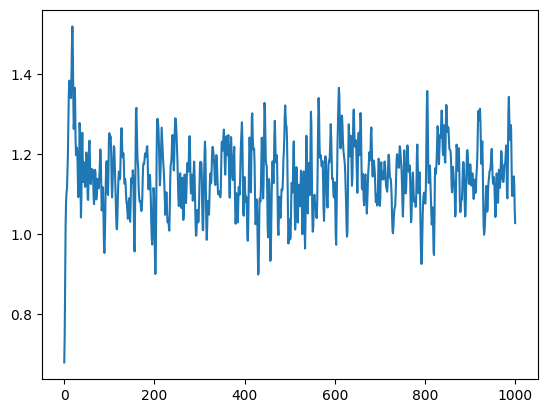

In [49]:
from pymbar import timeseries, MBAR
import numpy as np
import matplotlib.pyplot as plt

window_traj = "traj_files/traj_window_26_cv_0.68.traj" # Enter window trajectory
window = read(window_traj, index=":")

kB = 0.0083144626
T = 25 + 273.15
beta = 1.0 / (kB * T)

cv_k = np.zeros(len(window))

i = 0

for atoms in window:
    d = atoms.get_distance(4, 6, mic=True) - atoms.get_distance(4, 21, mic=True)
    cv_k[i] = d
    i += 1

sub_cv = []

t0, g, neff = timeseries.detect_equilibration(cv_k)
x_eq = cv_k[t0:]
idx = timeseries.subsample_correlated_data(x_eq, g=g)
sub_cv.append(x_eq[idx])
print("equil. frames:", t0, "g:", g, "indep. samples:", len(idx))
print("Collective Variable Mean: ",np.mean(cv_k))
print("Collective Variable Standard Deviation: ",np.std(cv_k))
plt.plot(cv_k)
plt.show()

# Summary of Stats Correlation Data:

## 1st  Image: equil. frames: 0  g: 116.84275 indep. samples: 172
## 9th  Image: equil. frames: 10 g: 3.4489763 indep. samples: 288
## 16th Image: equil. frames: 64 g: 1.4240708 indep. samples: 658
## 26th Image: equil. frames: 0  g: 3.2685254 indep. samples: 307
## 36th Image: equil. frames: 0  g: 7.4876857 indep. samples: 134

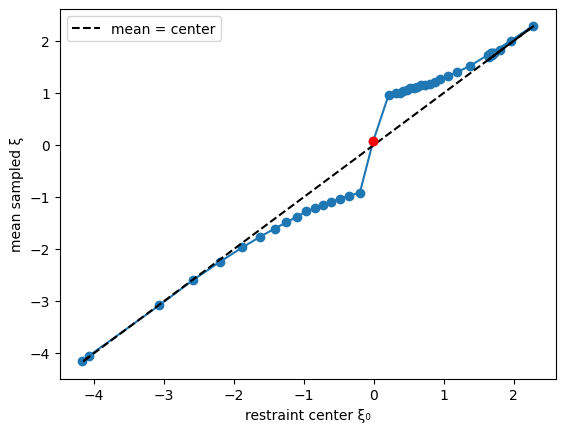

In [50]:
plt.plot(cv_0s, cv_xs_means, "o-")
plt.plot(cv_0s, cv_0s, "k--", label="mean = center")
plt.plot(cv_0s[17], cv_xs_means[17], "o-", c="red")
plt.xlabel("restraint center ξ₀")
plt.ylabel("mean sampled ξ")
plt.legend()
plt.show()

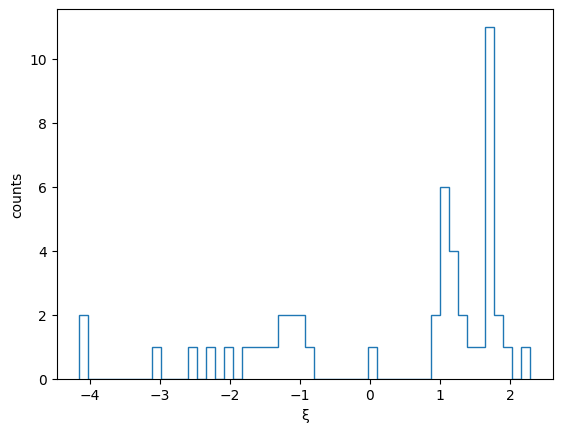

In [51]:
plt.hist(cv_xs_means, bins=50, histtype="step", density=False)
plt.xlabel("ξ")
plt.ylabel("counts")
plt.show()

In [45]:
all_frames = []
traj_files = sorted(Path('traj_files/').glob('traj_window_*_cv_*.traj'))
n_frames_per_win = 1001
n_windows = len(traj_files)
u_kn = np.zeros((n_windows, n_total), dtype=float)
N_k = np.full(n_windows, n_frames_per_win, dtype=int)
n_total = N_k.sum() # 50,050
T = 300  # Kelvin
beta = 1.0 / (kB * T)

cv_0s = np.loadtxt('centers.txt')
kappa_k = np.full(n_windows, 2.073)

cv_xs = np.zeros((n_windows, n_frames_per_win), dtype=float)
cv_xs_means = np.zeros(n_windows, dtype=float)
all_cvs = np.zeros(n_total, dtype=float)
all_epot = np.zeros(n_total, dtype=float)

col = 0
for i, traj_file in enumerate(traj_files): 
    window = read(str(traj_file), index=":")
    if len(window) != n_frames_per_win:
        raise ValueError(
            f"Window {i} ({traj_file}) has {len(window)} frames; expected {n_frames_per_win}."
        )
    for j, atoms in enumerate(window):
        d = atoms.get_distance(4, 6, mic=True) - atoms.get_distance(4, 21, mic=True)
        epot = float(np.asarray(atoms.get_potential_energy()).item())
        
        cv_xs[i,j] = d
        all_cvs[col] = d
        all_epot[col] = epot
        col += 1
        
        #all_frames.append(atoms)
        
    cv_xs_means[i] = cv_xs[i].mean()

u_unbiased = beta * all_epot[None, :]  # shape (1, n_total)
u_bias_kn = beta * 0.5 * kappa_k[:, None] * (all_cvs[None, :] - cv_0s[:, None]) ** 2
u_kn = u_unbiased + u_bias_kn

assert u_kn.shape == (n_windows, n_total), f"Unexpected u_kn shape: {u_kn.shape}"

mbar = MBAR(u_kn, N_k, initialize="BAR", solver_protocol="robust")

Saving outputs in: /Users/mauricioagurcia/Desktop/aspirin_hydrolysis/transition_path_search/mace_dynamics/umbrella_sampling
Raw mu from compute_multiple_expectations: [1.12333196e-01 2.51080973e-01 2.48646048e-01 1.21770423e-01
 3.23523364e-02 6.14919031e-02 3.88278910e-02 4.12418579e-02
 2.59258123e-02 2.26515646e-02 1.77221412e-02 9.37266685e-03
 4.52062551e-03 1.13166079e-03 1.49519902e-04 9.47485101e-06
 2.57510882e-07 1.94586997e-09 1.98528531e-12 8.44801894e-17
 6.55237324e-22 3.02474035e-24 2.89230053e-26 8.31460950e-25
 2.72628792e-24 4.76800406e-24 4.12048193e-22 2.91066869e-19
 6.05231688e-14 7.39594008e-10 3.01233520e-07 1.22759511e-05
 1.13119516e-04 3.86580330e-04 8.00302460e-04 1.09840028e-03
 1.34624196e-03 1.53820481e-03 5.47621833e-03]
Valid PMF bins: 39 / 40
  d =  -4.317 Å   F =   0.0208 eV   (n=209)
  d =  -4.139 Å   F =   0.0000 eV   (n=1164)
  d =  -3.962 Å   F =   0.0003 eV   (n=589)
  d =  -3.784 Å   F =   0.0187 eV   (n=40)
  d =  -3.428 Å   F =   0.0530 eV   (

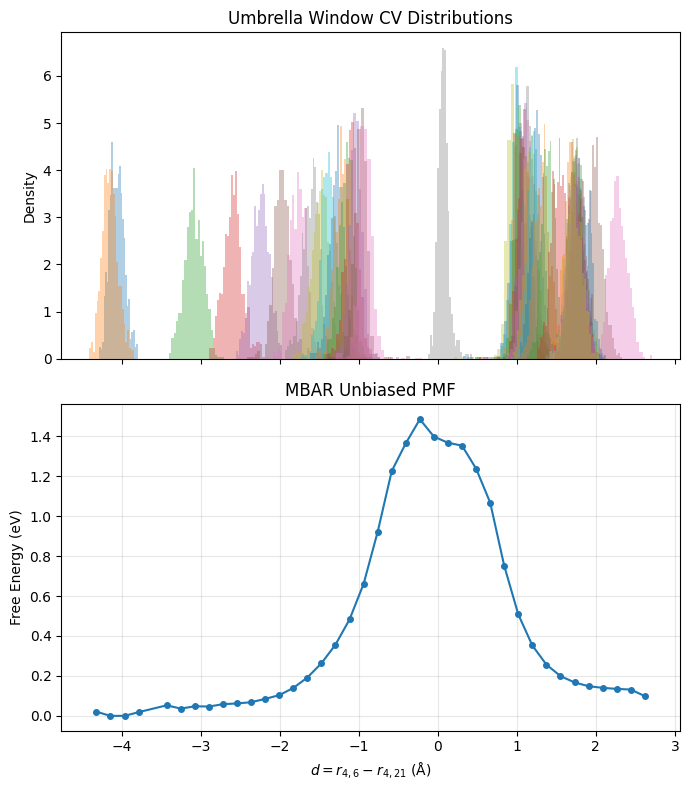

<Figure size 640x480 with 0 Axes>

In [46]:
import os
import warnings
import matplotlib.pyplot as plt
import numpy as np

print("Saving outputs in:", os.getcwd())

u_unbiased_n = beta * all_epot

n_bins = 40
bin_edges = np.linspace(all_cvs.min(), all_cvs.max(), n_bins + 1)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
bin_idx = np.clip(np.digitize(all_cvs, bin_edges) - 1, 0, n_bins - 1)

counts = np.bincount(bin_idx, minlength=n_bins)
active_bins = np.flatnonzero(counts > 0)
A_active = (bin_idx[None, :] == active_bins[:, None]).astype(float)

with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    exp_res = mbar.compute_multiple_expectations(A_active, u_unbiased_n)

probs_active = np.asarray(exp_res["mu"], dtype=float)
print("Raw mu from compute_multiple_expectations:", probs_active)

probs = np.zeros(n_bins, dtype=float)
probs[active_bins] = np.where(np.isfinite(probs_active) & (probs_active > 0), probs_active, 0.0)

f_i_kt = np.full(n_bins, np.nan, dtype=float)
pos = probs > 0
f_i_kt[pos] = -np.log(probs[pos])

f_ev = f_i_kt / beta
min_f = np.nanmin(f_ev) if np.any(pos) else 0.0
f_ev_shifted = f_ev - min_f

print(f"Valid PMF bins: {pos.sum()} / {n_bins}")
for c, f, cnt in zip(bin_centers, f_ev_shifted, counts):
    if np.isfinite(f):
        print(f"  d = {c:+7.3f} Å   F = {f:8.4f} eV   (n={cnt})")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 8), sharex=True)
for i in range(n_windows):
    ax1.hist(cv_xs[i], bins=25, density=True, alpha=0.35)
ax1.set_ylabel("Density")
ax1.set_title("Umbrella Window CV Distributions")

if np.any(pos):
    ax2.plot(bin_centers[pos], f_ev_shifted[pos], marker="o", markersize=4)
else:
    ax2.text(0.5, 0.5, "No positive bin probabilities returned", ha="center", va="center", transform=ax2.transAxes)

ax2.set_xlabel(r"$d = r_{4,6} - r_{4,21}$ (Å)")
ax2.set_ylabel("Free Energy (eV)")
ax2.set_title("MBAR Unbiased PMF")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
plt.savefig("pmf_mbar.png", dpi=300)
plt.close(fig)

### Next steps: Run more trajectories where you see gaps in the histogram to get a better idea of barrier height.